# Logistic Regression
**Name:** GUNTI RAHUL |  **Roll No:** CH.SC.U4CSE24211 
**Course:** Machine Learning (23CSE301)  |  **Lab Activity Book:** Chapter 6.6

## Exercise 1 - Graduate school admission
**Question:** how do GRE score, GPA and the prestige of the undergraduate institution (`rank`, 1 = highest) affect the chance of admission? Response `admit` is binary.

In [1]:
import numpy as np, pandas as pd, seaborn as sns, matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (accuracy_score, confusion_matrix, classification_report,
                             roc_curve, roc_auc_score, precision_recall_fscore_support)
df = pd.read_stata("https://stats.idre.ucla.edu/stat/stata/dae/binary.dta")
df["rank"] = df["rank"].astype(int)
print(df.shape); print(df.isna().sum().to_dict()); df.describe().round(2)

(400, 4)
{'admit': 0, 'gre': 0, 'gpa': 0, 'rank': 0}


,admit,gre,gpa,rank
count,400.00,400.00,400.00,400.00
mean,0.32,587.70,3.39,2.48
std,0.47,115.52,0.38,0.94
min,0.00,220.00,2.26,1.00
25%,0.00,520.00,3.13,2.00
50%,0.00,580.00,3.40,2.00
75%,1.00,660.00,3.67,3.00
max,1.00,800.00,4.00,4.00


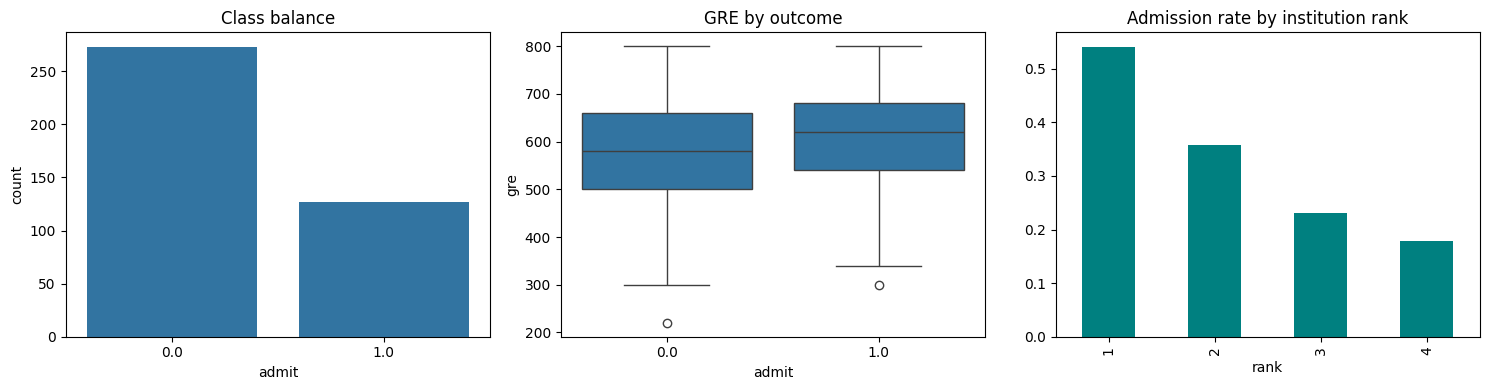

In [2]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
sns.countplot(x="admit", data=df, ax=ax[0]); ax[0].set_title("Class balance")
sns.boxplot(x="admit", y="gre", data=df, ax=ax[1]); ax[1].set_title("GRE by outcome")
df.groupby("rank").admit.mean().plot.bar(ax=ax[2], color="teal"); ax[2].set_title("Admission rate by institution rank")
plt.tight_layout(); plt.show()

In [3]:
X = pd.get_dummies(df[["gre", "gpa", "rank"]], columns=["rank"], drop_first=True).astype(float)
y = df["admit"]
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.25, random_state=262, stratify=y)
sc = StandardScaler().fit(Xtr[["gre", "gpa"]])
def prep(A):
    A = A.copy(); A[["gre", "gpa"]] = sc.transform(A[["gre", "gpa"]]); return A
clf = LogisticRegression(max_iter=1000).fit(prep(Xtr), ytr)
prob = clf.predict_proba(prep(Xte))[:, 1]; pred = (prob >= .5).astype(int)

print("Accuracy:", round(accuracy_score(yte, pred), 3), "| ROC-AUC:", round(roc_auc_score(yte, prob), 3))
print(classification_report(yte, pred, zero_division=0))
odds = pd.DataFrame({"coef": clf.coef_[0], "odds_ratio": np.exp(clf.coef_[0])}, index=X.columns).round(3); odds

Accuracy: 0.69 | ROC-AUC: 0.608
              precision    recall  f1-score   support

         0.0       0.71      0.91      0.80        68
         1.0       0.54      0.22      0.31        32

    accuracy                           0.69       100
   macro avg       0.63      0.57      0.56       100
weighted avg       0.66      0.69      0.64       100



,coef,odds_ratio
gre,0.380,1.463
gpa,0.347,1.415
rank_2,-0.449,0.638
rank_3,-0.945,0.389
rank_4,-1.246,0.288


**Interpreting odds ratios:** the scaled `gre`/`gpa` ratios are per one standard deviation. The `rank_2..4` ratios are relative to rank 1 and fall below 1, i.e. applicants from lower-ranked institutions have lower odds of admission.

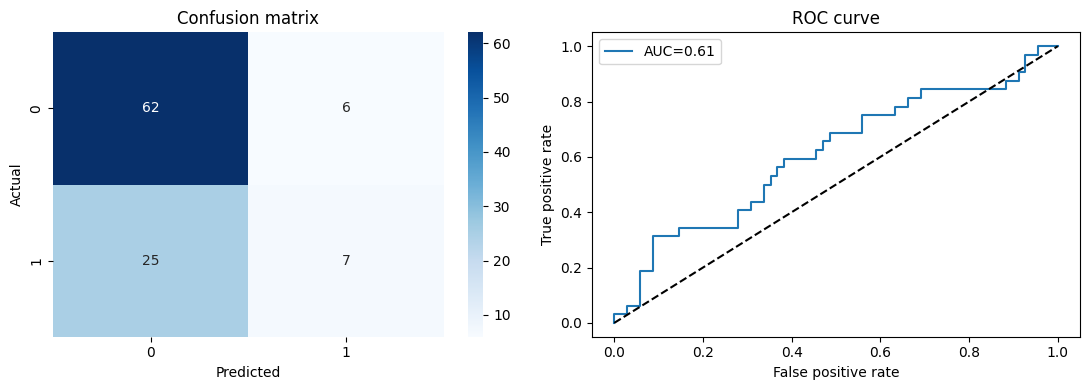

In [4]:
fpr, tpr, thr = roc_curve(yte, prob)
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
sns.heatmap(confusion_matrix(yte, pred), annot=True, fmt="d", cmap="Blues", ax=ax[0]); ax[0].set(xlabel="Predicted", ylabel="Actual", title="Confusion matrix")
ax[1].plot(fpr, tpr, label=f"AUC={roc_auc_score(yte, prob):.2f}"); ax[1].plot([0, 1], [0, 1], "k--"); ax[1].legend(); ax[1].set(xlabel="False positive rate", ylabel="True positive rate", title="ROC curve")
plt.tight_layout(); plt.show()

In [5]:
rows = []
for t in [0.3, 0.4, 0.5, 0.6]:
    p_, r_, f_, _ = precision_recall_fscore_support(yte, (prob >= t).astype(int), average="binary", zero_division=0)
    rows.append((t, round(p_, 3), round(r_, 3), round(f_, 3)))
pd.DataFrame(rows, columns=["threshold", "precision", "recall", "f1"])

,threshold,precision,recall,f1
0,0.3,0.400,0.688,0.506
1,0.4,0.367,0.344,0.355
2,0.5,0.538,0.219,0.311
3,0.6,0.500,0.031,0.059


Lowering the threshold raises recall at the cost of precision; the right cut-off depends on whether missing a likely admit or flagging a weak one is costlier.

## Exercise 2 - Disease susceptibility
**Data note:** the datatab.net example can't be downloaded programmatically, so a synthetic cohort (age, BMI, blood pressure, smoking) with a known risk structure is generated.

In [6]:
rng = np.random.default_rng(262); n = 600
pat = pd.DataFrame({"age": rng.integers(20, 80, n), "bmi": rng.normal(27, 4, n),
                    "bp": rng.normal(125, 15, n), "smoker": rng.integers(0, 2, n)})
z = -14 + .04 * pat.age + .15 * pat.bmi + .05 * pat.bp + .9 * pat.smoker
pat["disease"] = (rng.random(n) < 1 / (1 + np.exp(-z))).astype(int)
print("Prevalence:", pat.disease.mean().round(3))
print(pat.groupby("disease").mean().round(2))

Prevalence: 0.258
           age    bmi      bp  smoker
disease                              
0        47.62  26.31  122.38    0.42
1        57.22  27.82  133.56    0.71


In [7]:
X2, y2 = pat.drop(columns="disease"), pat["disease"]
Xtr2, Xte2, ytr2, yte2 = train_test_split(X2, y2, test_size=.25, random_state=262, stratify=y2)
sc2 = StandardScaler().fit(Xtr2)
m2 = LogisticRegression(max_iter=1000).fit(sc2.transform(Xtr2), ytr2)
p2 = m2.predict_proba(sc2.transform(Xte2))[:, 1]
print("ROC-AUC:", round(roc_auc_score(yte2, p2), 3)); print(classification_report(yte2, (p2 >= .5).astype(int)))
print(pd.Series(np.exp(m2.coef_[0]), index=X2.columns).round(2).sort_values(ascending=False).rename("odds ratio per 1 SD"))
person = pd.DataFrame({"age": [62], "bmi": [32], "bp": [150], "smoker": [1]})
print("Risk for a 62-year-old smoker, BMI 32, BP 150:", round(m2.predict_proba(sc2.transform(person))[0, 1], 3))

ROC-AUC: 0.776
              precision    recall  f1-score   support

           0       0.80      0.95      0.86       111
           1       0.67      0.31      0.42        39

    accuracy                           0.78       150
   macro avg       0.73      0.63      0.64       150
weighted avg       0.76      0.78      0.75       150

bp        2.54
age       2.13
smoker    1.96
bmi       1.79
Name: odds ratio per 1 SD, dtype: float64
Risk for a 62-year-old smoker, BMI 32, BP 150: 0.862


## Exercise 3 - Which product will a customer buy?
Multiclass (softmax) logistic regression on a synthetic retailer dataset: age, income and previous purchases predict Laptop / Book / Phone.

product
Phone     492
Book      346
Laptop    162
Name: count, dtype: int64
Accuracy: 0.68
              precision    recall  f1-score   support

        Book       0.70      0.79      0.74        86
      Laptop       0.70      0.17      0.27        41
       Phone       0.66      0.77      0.71       123

    accuracy                           0.68       250
   macro avg       0.69      0.58      0.58       250
weighted avg       0.68      0.68      0.65       250



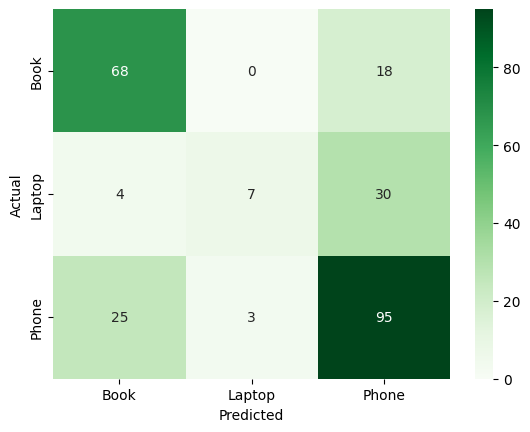

In [8]:
n = 1000; r = np.random.default_rng(262)
age = r.integers(18, 70, n); inc = r.normal(50, 15, n).clip(15); prev = r.integers(0, 15, n)
score = np.c_[-0.05 * (age - 30) + 0.02 * inc, 0.03 * (age - 45) + 0.1 * prev, 0.04 * inc - 0.02 * age] + r.normal(0, .7, (n, 3))
shop = pd.DataFrame({"age": age, "income": inc, "prev_purchases": prev, "product": np.array(["Laptop", "Book", "Phone"])[score.argmax(1)]})
print(shop["product"].value_counts())
Xtr3, Xte3, ytr3, yte3 = train_test_split(shop.drop(columns="product"), shop["product"], test_size=.25, random_state=262, stratify=shop["product"])
sc3 = StandardScaler().fit(Xtr3)
mc = LogisticRegression(max_iter=2000).fit(sc3.transform(Xtr3), ytr3)
p3 = mc.predict(sc3.transform(Xte3))
print("Accuracy:", round(accuracy_score(yte3, p3), 3)); print(classification_report(yte3, p3))
sns.heatmap(confusion_matrix(yte3, p3, labels=mc.classes_), annot=True, fmt="d", xticklabels=mc.classes_, yticklabels=mc.classes_, cmap="Greens")
plt.xlabel("Predicted"); plt.ylabel("Actual"); plt.show()

In [9]:
cust = pd.DataFrame({"age": [25, 55], "income": [70, 40], "prev_purchases": [3, 12]})
probs = pd.DataFrame(mc.predict_proba(sc3.transform(cust)), columns=mc.classes_).round(3)
probs["most likely"] = mc.predict(sc3.transform(cust)); pd.concat([cust, probs], axis=1)

,age,income,prev_purchases,Book,Laptop,Phone,most likely
0,25,70,3,0.006,0.197,0.797,Phone
1,55,40,12,0.855,0.017,0.128,Book


### Conclusion
Scaling the inputs makes coefficients comparable, ROC-AUC and threshold tables show more than raw accuracy, and softmax regression turns the same machinery into a multi-product recommender.